# Heart Disease Prediction System

**Live demo link:** *(pending deployment)*

> **Educational use only.** This notebook is a university learning exercise (AIC354 - Machine Learning Fundamentals, Assignment 2, Task 2). It is **not** a medical tool and its output is **not** a medical diagnosis.

This notebook adapts the *Titanic Passenger Survival Prediction System* notebook to a new problem, following the same steps: Import Libraries, Load Data, Understand/Pre-process, Feature Selection, Encoding, Training, Testing, Application, and Feedback.

## Introduction

##### **Definition** A binary classification ML task that predicts whether **heart disease is indicated (1)** or **not indicated (0)** for a patient, using four simple patient attributes.
##### **Application** Learning how a complete ML system is built (data, preprocessing, training, testing, application) on structured data.

## Dataset

- **Source:** UCI Machine Learning Repository, *Heart Disease* dataset (https://archive.ics.uci.edu/dataset/45/heart+disease).
- **Provided file:** `heart.csv` (used exactly as provided; this notebook never modifies it).
- **Variant:** the processed *Cleveland* version: 303 patients, 13 attributes plus the target column `num`.
- **Target (`num`):** original UCI values are 0 to 4. Value 0 means no heart disease; values 1 to 4 mean heart disease is present at increasing severity. As required, we convert it to a **binary target: 0 = no disease indicated, 1-4 = disease indicated**.

## Input and Output

### Inputs (the four selected features)

| **Feature** | **Meaning** | **Possible values** |
| ----------- | ----------- | ------------------- |
| **sex** | Sex of the patient | 0 = Female, 1 = Male |
| **cp** | Chest pain type | 1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic |
| **thalach** | Maximum heart rate achieved (beats per minute) | A number (71 to 202 in the dataset) |
| **exang** | Exercise-induced angina | 0 = No, 1 = Yes |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------- |
| **Heart disease** | Disease indicated (1), No disease indicated (0) |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction (Selecting Four Features)
- Step 5: Encoding and Scaling (Preprocessing Pipeline)
- Step 6: Execute the Training Phase
- Step 7: Execute the Testing Phase
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase

### Step 1: Import Libraries

In [1]:
"""
Purpose of this section:
------------------------
Import the tools we need: pandas/numpy for data, pickle to save the model,
scikit-learn for preprocessing, training and evaluation, matplotlib for one chart.
"""
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
------------------------
Load the Heart Disease dataset (heart.csv) into a pandas DataFrame and look at the first rows.
heart.csv must be in the same folder as this notebook.
"""
sample_data = pd.read_csv("heart.csv")

print("\n\nSample Data (first 5 rows):")
print("===========================\n")
print(sample_data.head())



Sample Data (first 5 rows):

   age  sex  cp  trestbps  chol  fbs  ...  exang  oldpeak  slope   ca  thal  num
0   63    1   1       145   233    1  ...      0      2.3      3  0.0   6.0    0
1   67    1   4       160   286    0  ...      1      1.5      2  3.0   3.0    2
2   67    1   4       120   229    0  ...      1      2.6      2  2.0   7.0    1
3   37    1   3       130   250    0  ...      0      3.5      3  0.0   3.0    0
4   41    0   2       130   204    0  ...      0      1.4      1  0.0   3.0    0

[5 rows x 14 columns]


### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
------------------------
Understand the data: attribute names, number of instances, data types,
missing values, and the original target values.
"""
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(list(sample_data.columns))

print("\n\nNumber of Instances in Sample Data:", sample_data.shape[0])
print("Number of Columns in Sample Data:  ", sample_data.shape[1])

print("\n\nMissing Values per Column:")
print("==========================\n")
print(sample_data.isnull().sum())

print("\n\nOriginal Target (num) Value Counts:")
print("===================================\n")
print(sample_data["num"].value_counts().sort_index())



Attributes in Sample Data:

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


Number of Instances in Sample Data: 303
Number of Columns in Sample Data:   14


Missing Values per Column:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


Original Target (num) Value Counts:

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data

Two things are needed here:

1. **Binary target.** The original target `num` has values 0 to 4. We create a new column `target`: **0 = no disease indicated** (`num` = 0) and **1 = disease indicated** (`num` = 1, 2, 3, 4).
2. **Missing values.** Only `ca` (4 missing) and `thal` (2 missing) have missing values. We do **not** use these two attributes, so none of our four selected features has missing values. Even so, our preprocessing pipeline (Step 5) includes an *imputer*, so a missing value would be handled safely during training and prediction.

The original `heart.csv` file is **not** changed; the new column exists only in memory.

In [4]:
# Create the binary target in memory (0 = no disease, 1-4 = disease)
sample_data["target"] = (sample_data["num"] > 0).astype(int)

print("\n\nBinary Target (target) Value Counts:")
print("====================================\n")
print(sample_data["target"].value_counts().sort_index())
print("\n0 = no disease indicated, 1 = disease indicated")



Binary Target (target) Value Counts:

target
0    164
1    139
Name: count, dtype: int64

0 = no disease indicated, 1 = disease indicated


### Step 4: Feature Extraction (Selecting Four Features)

The assignment requires **exactly four** input attributes. We selected these, using simple reasons a beginner can follow:

| Feature | Why it was selected |
| ------- | ------------------- |
| **sex** | Heart disease rates differ between men and women, and it is a simple, easy-to-enter value. |
| **cp** (chest pain type) | Chest pain pattern is one of the most important clinical signs; in this dataset about 73% of "asymptomatic" (type 4) patients have disease, versus about 18-30% for the other types. |
| **thalach** (maximum heart rate) | A lower maximum heart rate during exercise is a well-known sign of reduced heart fitness. It is the one numeric feature. |
| **exang** (exercise-induced angina) | Chest pain brought on by exercise is a direct warning sign, and it is a simple yes/no question. |

All four are easy for an ordinary user to type into a web form, and none of them has missing values. The target (`target`/`num`) is **not** used as an input.

In [5]:
"""
Purpose of this section:
------------------------
Select the four input features (X) and the output label (y).
The order below is used everywhere: training, testing, and the Streamlit app.
"""
FEATURES = ["sex", "cp", "thalach", "exang"]

X = sample_data[FEATURES]
y = sample_data["target"]

print("Selected input features:", FEATURES)
print("Number of input features:", len(FEATURES))
print("\nInput data shape :", X.shape)
print("Output label shape:", y.shape)
print("\nMissing values in the four selected features:", int(X.isnull().sum().sum()))

Selected input features: ['sex', 'cp', 'thalach', 'exang']
Number of input features: 4

Input data shape : (303, 4)
Output label shape: (303,)

Missing values in the four selected features: 0


### Step 5: Encoding and Scaling (Preprocessing Pipeline)

The Titanic notebook used Label Encoding because all its inputs were text. Here the inputs are already numbers, but they are of two kinds, so each kind gets suitable preprocessing:

- **Numeric feature (`thalach`)**: fill missing values with the median, then **scale** it (StandardScaler) so its size does not dominate the model.
- **Category features (`sex`, `cp`, `exang`)**: fill missing values with the most common value, then **One-Hot Encode** them. (`cp` is a set of categories, not a quantity: "type 4" is not "twice" "type 2".)

We bundle the preprocessing and the SVC model into one **Pipeline**. A pipeline is *fitted on the training data only* (Step 6), which prevents **data leakage** from the test data. Because the same pipeline object is saved and later loaded by the app, training and prediction always use exactly the same preprocessing.

In [6]:
numeric_features = ["thalach"]
categorical_features = ["sex", "cp", "exang"]

# Preprocessing for the numeric feature: fill missing values, then scale
numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Preprocessing for category features: fill missing values, then one-hot encode
categorical_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# Apply the right steps to the right columns (selected by column NAME, not position)
preprocessor = ColumnTransformer([
    ("numeric", numeric_steps, numeric_features),
    ("categorical", categorical_steps, categorical_features),
])

# Preprocessing + Support Vector Classifier in ONE pipeline (not trained yet)
svc_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("svc", SVC(random_state=0)),
])

print(svc_pipeline)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['thalach']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex'

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [7]:
"""
Purpose of this section:
------------------------
Split the data into 80% training and 20% testing data.
- random_state=0 gives the same split every time.
- stratify=y keeps the same share of disease / no-disease patients in both parts.
  (Titanic used shuffle=False because its rows were kept in order; here we shuffle
  and stratify, which is the safer choice for this dataset.)
"""
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)

print("Training Data shape:", X_train.shape)
print("Testing Data shape: ", X_test.shape)
print("\nDisease share in training data:", round(y_train.mean(), 3))
print("Disease share in testing data: ", round(y_test.mean(), 3))

Training Data shape: (242, 4)
Testing Data shape:  (61, 4)

Disease share in training data: 0.459
Disease share in testing data:  0.459


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
# X_train holds the input vectors and y_train holds the output labels of the training data
print("Input vectors (train) shape:", X_train.shape)
print("Output labels (train) shape:", y_train.shape)
print("\nFirst 3 training input vectors:")
print(X_train.head(3))

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)

First 3 training input vectors:
     sex  cp  thalach  exang
111    1   4      144      1
52     1   4      153      0
173    0   4      157      0


#### Step 6.3: Train the Support Vector Classifier

In [9]:
"""
Purpose of this section:
------------------------
Train the pipeline on the TRAINING data only. This fits the imputers, the scaler,
the one-hot encoder AND the SVC model, all using training data only.
"""
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_pipeline.fit(X_train, y_train)

print(svc_pipeline)



Training the Support Vector Classifier on Training Data

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['thalach']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]

#### Step 6.4: Save the Trained Model

In [10]:
# Save the trained pipeline (preprocessing + SVC) in ONE file
pickle.dump(svc_pipeline, open("heart_disease_model.pkl", "wb"))
print("Saved: heart_disease_model.pkl")

Saved: heart_disease_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [11]:
# X_test holds the input vectors and y_test holds the true labels of the testing data
print("Input vectors (test) shape:", X_test.shape)
print("Output labels (test) shape:", y_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [12]:
model = pickle.load(open("heart_disease_model.pkl", "rb"))
print("Model loaded from heart_disease_model.pkl")

Model loaded from heart_disease_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [13]:
# The pipeline automatically applies the saved preprocessing before predicting
model_predictions = model.predict(X_test)

results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = model_predictions

print("\n\nPredictions Returned by heart_disease_model (first 10 test rows):")
print("=================================================================\n")
print(results.head(10))



Predictions Returned by heart_disease_model (first 10 test rows):

     sex  cp  thalach  exang  Actual  Predicted
125    0   2      175      0       0          0
83     1   3      150      1       1          0
53     1   2      188      0       0          0
45     1   3      165      0       1          0
248    1   4      168      0       1          0
211    1   1      182      1       1          0
36     1   4      120      1       1          1
106    1   4      162      1       1          1
120    1   4      150      1       1          1
31     1   4      160      1       1          1


#### Step 7.4: Calculate the Accuracy Score

In [14]:
model_accuracy_score = accuracy_score(y_test, model_predictions)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 4))
print("(", int((y_test.values == model_predictions).sum()), "of", len(y_test), "testing patients predicted correctly )")



Accuracy Score:

0.7705
( 47 of 61 testing patients predicted correctly )


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                precision    recall  f1-score   support

No disease (0)       0.72      0.94      0.82        33
   Disease (1)       0.89      0.57      0.70        28

      accuracy                           0.77        61
     macro avg       0.80      0.76      0.76        61
  weighted avg       0.80      0.77      0.76        61


Confusion Matrix:

                    Predicted: No disease  Predicted: Disease
Actual: No disease                     31                   2
Actual: Disease                        12                  16


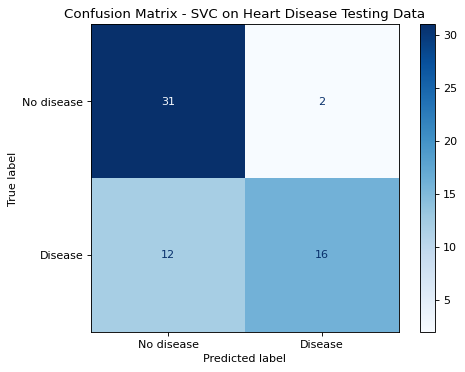

In [15]:
print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    y_test, model_predictions,
    target_names=["No disease (0)", "Disease (1)"]
))

conf_matrix = confusion_matrix(y_test, model_predictions)
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No disease", "Actual: Disease"],
    columns=["Predicted: No disease", "Predicted: Disease"],
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

ConfusionMatrixDisplay(conf_matrix, display_labels=["No disease", "Disease"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [16]:
"""
Purpose of this section:
------------------------
Four example values stand in for what a user would type. In the Streamlit app
the user picks these values in a web form instead.
  sex: 0 = Female, 1 = Male
  cp : 1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic
  thalach: maximum heart rate (beats per minute)
  exang: 0 = No, 1 = Yes
"""
sex_input = 1
cp_input = 4
thalach_input = 120
exang_input = 1

print(f"sex: {sex_input}, cp: {cp_input}, thalach: {thalach_input}, exang: {exang_input}")

sex: 1, cp: 4, thalach: 120, exang: 1


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [17]:
user_input = pd.DataFrame({
    "sex": [sex_input],
    "cp": [cp_input],
    "thalach": [thalach_input],
    "exang": [exang_input],
})[FEATURES]   # same four columns, same order as training

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

   sex  cp  thalach  exang
0    1   4      120      1


#### Step 8.3: Preprocessing of the Feature Vector

No separate encoding step is needed: the saved pipeline scales and encodes the input automatically, exactly as it did during training.

#### Step 8.4: Load the Saved Model

In [18]:
model = pickle.load(open("heart_disease_model.pkl", "rb"))
print("Model loaded from heart_disease_model.pkl")

Model loaded from heart_disease_model.pkl


#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model on the Feature Vector of an unseen instance and return Prediction to the User

In [19]:
predicted_target = model.predict(user_input)[0]

if predicted_target == 1:
    prediction = "DISEASE INDICATED"
else:
    prediction = "NO DISEASE INDICATED"

print("\n** Prediction **")
print(prediction)
print("\n(Educational use only - not a medical diagnosis.)")


** Prediction **
DISEASE INDICATED

(Educational use only - not a medical diagnosis.)


In [20]:
# A few more demonstration predictions with the same trained model
examples = pd.DataFrame({
    "sex":     [1, 0, 1],
    "cp":      [4, 2, 3],
    "thalach": [120, 170, 150],
    "exang":   [1, 0, 0],
})[FEATURES]

examples["Prediction"] = [
    "DISEASE INDICATED" if p == 1 else "NO DISEASE INDICATED"
    for p in model.predict(examples)
]
print(examples)

   sex  cp  thalach  exang            Prediction
0    1   4      120      1     DISEASE INDICATED
1    0   2      170      0  NO DISEASE INDICATED
2    1   3      150      0  NO DISEASE INDICATED


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts
No real users or medical experts have reviewed this system yet, so no feedback is claimed here.

#### Step 9.2: Make a List of Potential Improvements
1. Use more of the 13 available attributes (for example `oldpeak`, `ca`, `thal`, `age`); the assignment limits this version to four.
2. Use a larger dataset: 303 patients is small, so the test results come from only 61 patients and can change a lot with a different split.
3. Use cross-validation for a more reliable accuracy estimate.
4. Compare other models (for example Logistic Regression, Random Forest) with SVC.

#### Step 9.3: Improve the Model Based on Feedback
A next version would apply the improvements above, then repeat Steps 6 and 7 to confirm the new model performs better before replacing `heart_disease_model.pkl`.

## Conclusion
Using only four attributes (sex, chest pain type, maximum heart rate, exercise-induced angina), the Support Vector Classifier reached an accuracy of **0.77** on the held-out testing data (47 of 61 patients; the model was trained on 242 patients). For the "disease indicated" class, precision was 0.89, recall 0.57 and F1-score 0.70 (see Step 7.5 for the full report and confusion matrix). Because the dataset is small and only four attributes are used, these results are a learning example and should not be treated as medical evidence.